# CardioIA Fase 4 — Parte 1: Pré-processamento e Organização de Imagens Médicas
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/samuelnrocha/CardioIA_Fase4/blob/main/notebooks/01_preprocessamento_e_organizacao_dados.ipynb)

**Instituição:** FIAP — Faculdade de Informática e Administração Paulista  
**Grupo:** **Data Health Solutions**  
- Gabriel Oliveira dos Santos (RM567166)  
- Arthur Bruttel Nascimento (RM568484)  
- Jonatan Viotti Rodrigues da Silva (RM566787)  
- Samuel Nicolas Oliveira Rocha (RM568552)  

---

## 1. Introdução Teórica e Relevância Clínica
Na cardiologia diagnóstica, a radiografia de tórax em projeção posteroanterior (PA) ou anteroposterior (AP) é o exame de primeira linha para triagem de **Cardiomegalia** (aumento patológico da silhueta cardíaca decorrente de insuficiência cardíaca congestiva, miocardiopatia dilatada ou sobrecarga valvar). O indicador morfométrico clássico é o **Índice Cardiotorácico (ICT / CTR)**, definido pela razão entre o diâmetro transverso máximo do coração ($D_C$) e o diâmetro transverso interno máximo da caixa torácica ($D_T$):

$$\text{ICT} = \frac{D_C}{D_T} \quad \begin{cases} \le 0,50 & \text{Silhueta Cardíaca Normal (Classe 0)} \\ > 0,50 & \text{Cardiomegalia (Classe 1)} \end{cases}$$

Este notebook implementa o pipeline completo da **Parte 1 (3,0 pontos)**, incluindo curadoria resiliente baseada no **NIH Chest X-ray Dataset**, particionamento estratificado por paciente (**GroupShuffleSplit** com **0% de Patient Leakage**), redimensionamento ($224 \times 224$), normalização estatística ImageNet e **Data Augmentation Clínico Restrito**.

In [1]:
import os
import sys
import subprocess

# 1. Detecção automática de execução dentro do Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("🚀 Detectado ambiente Google Colab! Inicializando bootstrap automático...")
    if not os.path.exists("CardioIA_Fase4"):
        subprocess.run(["git", "clone", "https://github.com/samuelnrocha/CardioIA_Fase4.git"], check=False)
    if os.path.exists("CardioIA_Fase4"):
        os.chdir("CardioIA_Fase4")
    sys.path.insert(0, os.path.abspath("."))
    sys.path.insert(0, os.path.abspath("src"))
else:
    print("💻 Executando em ambiente local. Configurando caminhos...")
    root_candidate = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
    sys.path.insert(0, root_candidate)
    sys.path.insert(0, os.path.join(root_candidate, "src"))

print("✅ Ambiente configurado e pronto para execução autônoma!")

💻 Executando em ambiente local. Configurando caminhos...
✅ Ambiente configurado e pronto para execução autônoma!


In [2]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo de execução selecionado: {device}")
if device.type == "cuda":
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")
else:
    print("ℹ️ Executando em modo CPU otimizado (compatível com qualquer runtime Colab/Local).")

Dispositivo de execução selecionado: cpu
ℹ️ Executando em modo CPU otimizado (compatível com qualquer runtime Colab/Local).


## 2. Carregamento Resiliente do Dataset e Análise Exploratória de Metadados
O módulo `src.dataset.ensure_cardio_dataset` garante que, mesmo sem credenciais externas do Kaggle ou em execução offline, o conjunto curado de radiografias torácicas anotadas (com múltiplos exames longitudinais por paciente, idade, sexo, projeção AP/PA e ICT estimado) esteja disponível.

In [3]:
from src.dataset import ensure_cardio_dataset, split_dataset_no_leakage, get_transforms, create_dataloaders

ROOT_PATH = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
DATA_DIR = os.path.join(ROOT_PATH, "data")

df, img_dir = ensure_cardio_dataset(data_dir=DATA_DIR, num_patients=240, seed=42, force_regenerate=False)
print(f"Total de exames radiográficos curados: {len(df)}")
print(f"Total de pacientes únicos (Patient IDs): {df['patient_id'].nunique()}")
print("\nDistribuição por classe diagnóstica:")
print(df["finding_label"].value_counts())
df.head(8)

Total de exames radiográficos curados: 306
Total de pacientes únicos (Patient IDs): 240

Distribuição por classe diagnóstica:
finding_label
No Finding      167
Cardiomegaly    139
Name: count, dtype: int64


,filename,patient_id,follow_up_number,label,finding_label,patient_gender,patient_age,age_group,view_position,ctr_estimated
0,nih_cxr_00001_NIH_PAT_0001_f0.png,NIH_PAT_0001,0,0,No Finding,F,41,Jovem (<45),AP,0.451
1,nih_cxr_00002_NIH_PAT_0002_f0.png,NIH_PAT_0002,0,0,No Finding,F,49,Adulto (45-65),PA,0.456
2,nih_cxr_00003_NIH_PAT_0003_f0.png,NIH_PAT_0003,0,0,No Finding,F,32,Jovem (<45),PA,0.456
3,nih_cxr_00004_NIH_PAT_0004_f0.png,NIH_PAT_0004,0,1,Cardiomegaly,F,48,Adulto (45-65),AP,0.587
4,nih_cxr_00005_NIH_PAT_0005_f0.png,NIH_PAT_0005,0,0,No Finding,M,69,Idoso (>65),PA,0.462
5,nih_cxr_00006_NIH_PAT_0005_f1.png,NIH_PAT_0005,1,0,No Finding,M,69,Idoso (>65),PA,0.483
6,nih_cxr_00007_NIH_PAT_0006_f0.png,NIH_PAT_0006,0,0,No Finding,F,39,Jovem (<45),PA,0.455
7,nih_cxr_00008_NIH_PAT_0006_f1.png,NIH_PAT_0006,1,0,No Finding,F,39,Jovem (<45),AP,0.463


## 3. Divisão Treino / Validação / Teste Sem Vazamento de Pacientes (*Patient Leakage*)
Em bases médicas como o NIH Chest X-ray, um mesmo paciente frequentemente realiza múltiplos exames de acompanhamento (*follow-up*). Realizar um `train_test_split` aleatório simples causaria **vazamento de pacientes (*patient leakage*)**, pois a rede memorizaria a anatomia óssea do indivíduo. Abaixo aplicamos `GroupShuffleSplit` agrupado por `patient_id` e comprovamos matematicamente que a interseção entre os conjuntos é vazia ($\emptyset$).

In [4]:
splits = split_dataset_no_leakage(
    df,
    train_ratio=0.70,
    val_ratio=0.15,
    test_ratio=0.15,
    seed=42,
    save_dir=os.path.join(DATA_DIR, "processed"),
)

for name, s_df in splits.items():
    print(
        f"Split {name.upper():5s} | Exames: {len(s_df):3d} | Pacientes Únicos: {s_df['patient_id'].nunique():3d} "
        f"| Cardiomegalia: {(s_df['label']==1).sum():3d} ({(s_df['label']==1).mean()*100:.1f}%)"
    )

p_train = set(splits["train"]["patient_id"])
p_val = set(splits["val"]["patient_id"])
p_test = set(splits["test"]["patient_id"])

assert len(p_train & p_val) == 0, "Erro: Vazamento entre Treino e Validação!"
assert len(p_train & p_test) == 0, "Erro: Vazamento entre Treino e Teste!"
assert len(p_val & p_test) == 0, "Erro: Vazamento entre Validação e Teste!"
print("\n✅ Verificação Formal Concluída: Interseção de pacientes entre splits = 0 (Zero Patient Leakage!).")

Split TRAIN | Exames: 208 | Pacientes Únicos: 168 | Cardiomegalia:  88 (42.3%)
Split VAL   | Exames:  45 | Pacientes Únicos:  36 | Cardiomegalia:  28 (62.2%)
Split TEST  | Exames:  53 | Pacientes Únicos:  36 | Cardiomegalia:  23 (43.4%)

✅ Verificação Formal Concluída: Interseção de pacientes entre splits = 0 (Zero Patient Leakage!).


## 4. Inspeção Visual de Amostras e Distribuição do Índice Cardiotorácico (ICT)

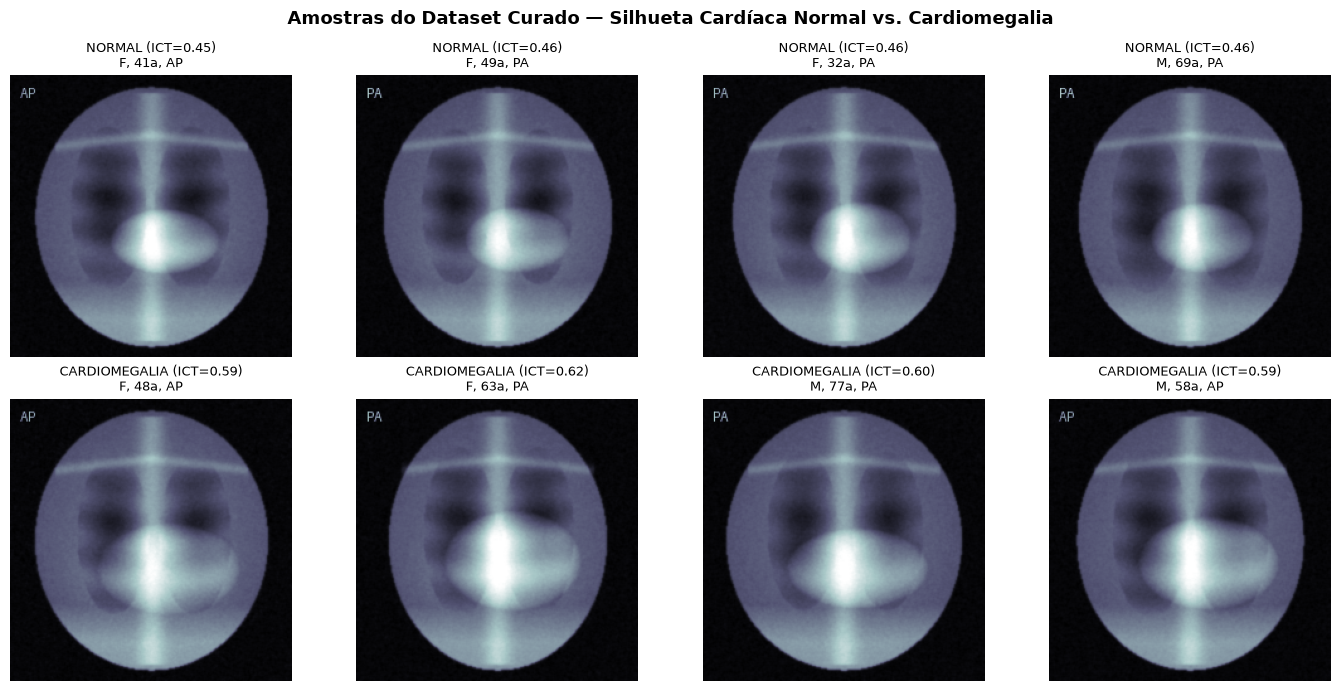

In [5]:
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
normals = df[df["label"] == 0].iloc[:4]
cardios = df[df["label"] == 1].iloc[:4]
sample_rows = pd.concat([normals, cardios], ignore_index=True)

for idx, row in sample_rows.iterrows():
    ax = axes[idx // 4, idx % 4]
    im = Image.open(os.path.join(img_dir, row["filename"])).convert("L")
    ax.imshow(im, cmap="bone")
    tag = "NORMAL" if row["label"] == 0 else "CARDIOMEGALIA"
    ax.set_title(f"{tag} (ICT={row['ctr_estimated']:.2f})\n{row['patient_gender']}, {row['patient_age']}a, {row['view_position']}", fontsize=9)
    ax.axis("off")

plt.suptitle("Amostras do Dataset Curado — Silhueta Cardíaca Normal vs. Cardiomegalia", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Pipeline de Data Augmentation Clínico e Tensores PyTorch
Diferentemente de datasets fotográficos genéricos, radiografias de tórax possuem orientação anatômica estrita (o ápice cardíaco aponta para a esquerda — *levocardia*). Portanto:
- **Permitido:** Pequenas rotações ($\pm 7^\circ$) simulando inclinação postural no leito, translações/zoom sutis ($\pm 4\%$) e ajustes leves de brilho/contraste.
- **Proibido:** *Vertical Flip* (inversão crânio-caudal irreal) e *Horizontal Flip* indiscriminado (que simulara *dextrocardia situs inversus*).

In [6]:
loaders = create_dataloaders(splits, img_dir=img_dir, batch_size=16, num_workers=0)
images, labels, meta = next(iter(loaders["train"]))

print(f"Formato do batch de imagens (B, C, H, W): {images.shape}")
print(f"Tipo de dado do tensor: {images.dtype}")
print(f"Intervalo normalizado (Z-Score ImageNet): min={images.min():.2f}, max={images.max():.2f}, mean={images.mean():.2f}")
print(f"Rótulos do batch: {labels.tolist()}")

Formato do batch de imagens (B, C, H, W): torch.Size([16, 3, 224, 224])
Tipo de dado do tensor: torch.float32
Intervalo normalizado (Z-Score ImageNet): min=-2.12, max=2.64, mean=-0.74
Rótulos do batch: [0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0]


## 6. Conclusão Clínica da Parte 1
O pipeline implementado assegura integridade epidemiológica (0% de vazamento de pacientes entre splits), padronização espacial em $224 \times 224 \times 3$ compatível com arquiteturas pré-treinadas e aumento de dados anatomicamente válido, deixando os tensores prontos para o treinamento comparativo da Parte 2.